# Check convergence 

In [1]:
import cobra
import pandas as pd
import numpy as np
import scipy
import warnings
import seaborn as sns
from collections import OrderedDict
from os import listdir
import matplotlib.pyplot as plt

from reframed.community.model import Community
from reframed import Environment, set_default_solver
from steadiercom.cli import load_communities,load_media_db

import sys
sys.path.append("../functions/")
from convergence import SteadierSampleConvergence
from convergence import std_sample_size,std_sampling_grouped,std_sampling_grouped_freq


In [2]:
%load_ext autoreload
%autoreload 2

### Gut microbiome community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 1:20 => the cells increase in density by 20 times)

$$
X_1/X_0 = 21 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(20)}{t}
$$

**Methods (From Venturelli et al. 2018): 1:20 dilution every 24 h**

In [3]:
np.log(20)/24

np.float64(0.12482217806474961)

In [4]:
mediadb = "../data/Venturelli2018/generated/media_db.tsv"#path to mediadb
medium = "LB_extend"
growth = np.log(20)/24# average growth rate

models = ["../models/Venturelli2018/species_used_noO2/"+name for name in listdir("../models/Venturelli2018/species_used_noO2/")]
communities = "../data/Venturelli2018/generated/communities_steadiercom_no_abundance/NONE_abundance.tsv"

comm_id = "NONE"

output_dir = "../output/Venturelli2018/convergence_test_no_abundance//"

In [25]:
dfs = []
for d in listdir("../output/Venturelli2018/convergence_test_no_abundance/"):
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/convergence_test_no_abundance/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)
dfs_tot = dfs_tot.T.drop_duplicates().T
dfs_tot.columns = np.arange(0,dfs_tot.shape[1])

# Separate positive and degative values
pos = dfs_tot[dfs_tot>0].dropna(how="all").copy()
neg = dfs_tot[dfs_tot<0].dropna(how="all").map(abs).copy()

neg["type"]="neg"
pos["type"]="pos"
neg.set_index("type",append=True,inplace=True)
pos.set_index("type",append=True,inplace=True)

dfs_tot_abs_nan = pd.concat([pos,neg],axis=0)
dfs_tot_abs = dfs_tot_abs_nan.fillna(0)

In [26]:
dfs_tot_abs.mean().mean()

np.float64(0.01245423255282189)

### Plotting standard deviation based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the standard deviation across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [27]:
base = 10
sample_sizes = [int(base * 2**i) for i in range(12)] 
sample_sizes = [s for s in sample_sizes if s<10000]

sample_sizes_higher_res = np.arange(1000,11000,1000)
sample_sizes_lower_res = np.arange(100,1000,100)


datas,datas_cv = std_sample_size(dfs_tot_abs,sample_sizes)
datas_higher_res,datas_higher_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_higher_res)
datas_lower_res,datas_lower_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_lower_res)

Text(0.5, 0, 'Number of samples')

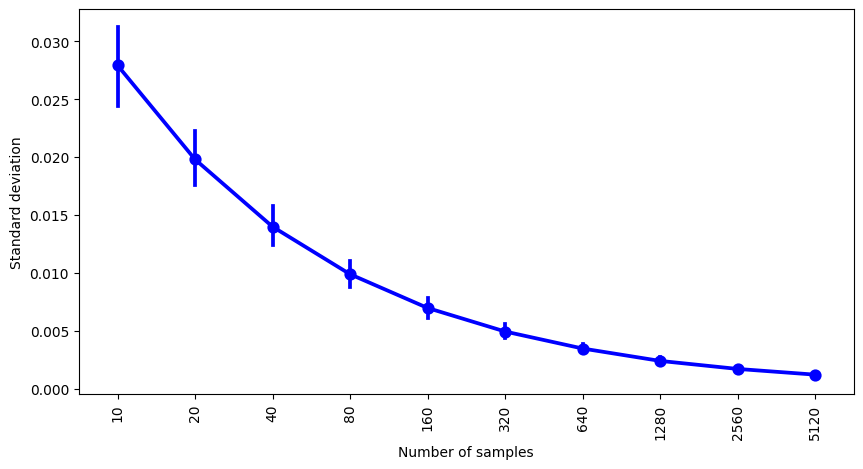

In [28]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)

ax.set_ylabel("Standard deviation")
ax.set_xlabel("Number of samples")
#plt.savefig("figures_meeting/convergence_gut_noabund.png",bbox_inches="tight")

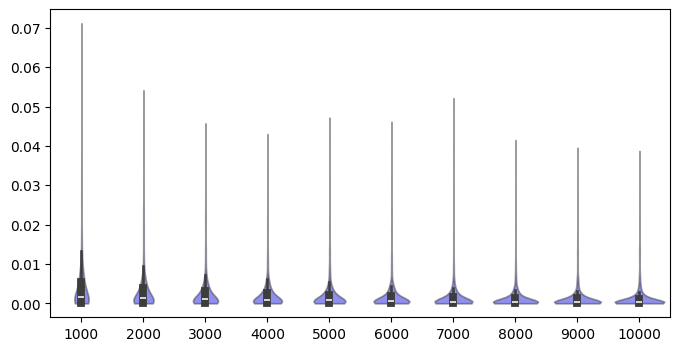

In [24]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,5e-])

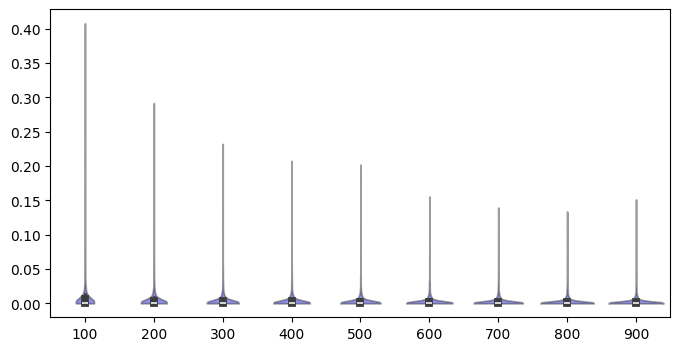

In [29]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_lower_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

### Plotting standard deviation based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [14]:
statistics,statistics_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes)

statistics_higher_res,statistics_higher_res_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes_higher_res)
       

(0.0, 0.2)

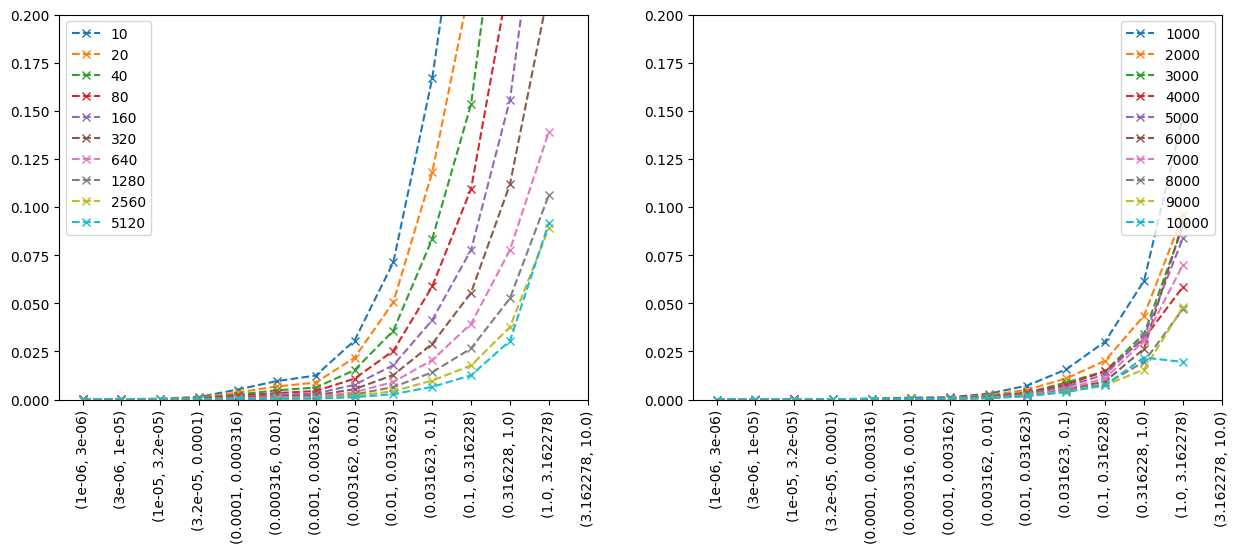

In [15]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))

ax1 = pd.DataFrame(statistics).plot(ax=ax1,marker="x",linestyle="--")
ax1.set_xticks(np.arange(0,len(pd.DataFrame(statistics).index.values)))
ax1.set_xticklabels(pd.DataFrame(statistics).index.values,rotation=90)
ax1.legend(loc="upper left")
ax1.set_ylim([0,0.2])

ax2 = pd.DataFrame(statistics_higher_res).plot(ax=ax2,marker="x",linestyle="--")
ax2.set_xticks(np.arange(0,len(pd.DataFrame(statistics_higher_res).index.values)))
ax2.set_xticklabels(pd.DataFrame(statistics_higher_res).index.values,rotation=90)
ax2.legend(loc="upper right")
ax2.set_ylim([0,0.2])

(0.0, 100.0)

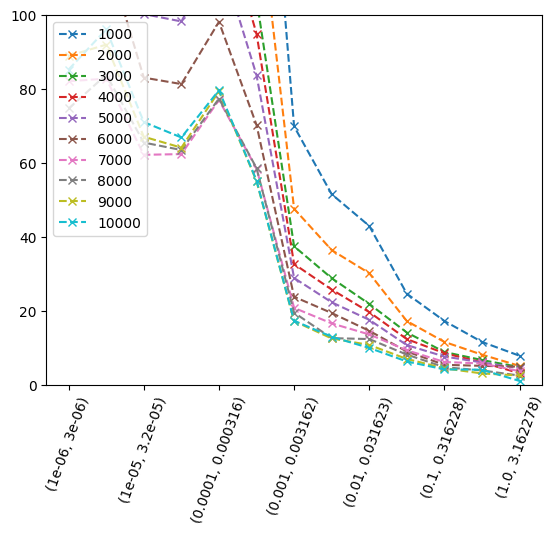

In [16]:
ax = pd.DataFrame(statistics_higher_res_cv).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)
plt.legend(loc="upper left")
ax.set_ylim([0,100])

In [17]:
stats_high_res = pd.DataFrame(statistics_higher_res_cv)
diff = (stats_high_res.T.iloc[1:].reset_index(drop=True)-stats_high_res.T.iloc[:-1].reset_index(drop=True))

index = pd.Index(list(zip(np.arange(1000,10000,1000),np.arange(2000,11000,1000))))
diff.set_index(keys=index,inplace=True)

In [18]:
diff.T.mean()

1000  2000    -39.723846
2000  3000    -21.423785
3000  4000     -6.813113
4000  5000     -6.379677
5000  6000     -8.927884
6000  7000    -11.588955
7000  8000     -1.049282
8000  9000      1.294088
9000  10000     0.455496
dtype: float64

**Sort based on frequency**

In [19]:
statistics_freq,statistics_freq_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes)
statistics_freq_higher_res, statistics_freq_higher_res_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes_higher_res)

(0.0, 0.05)

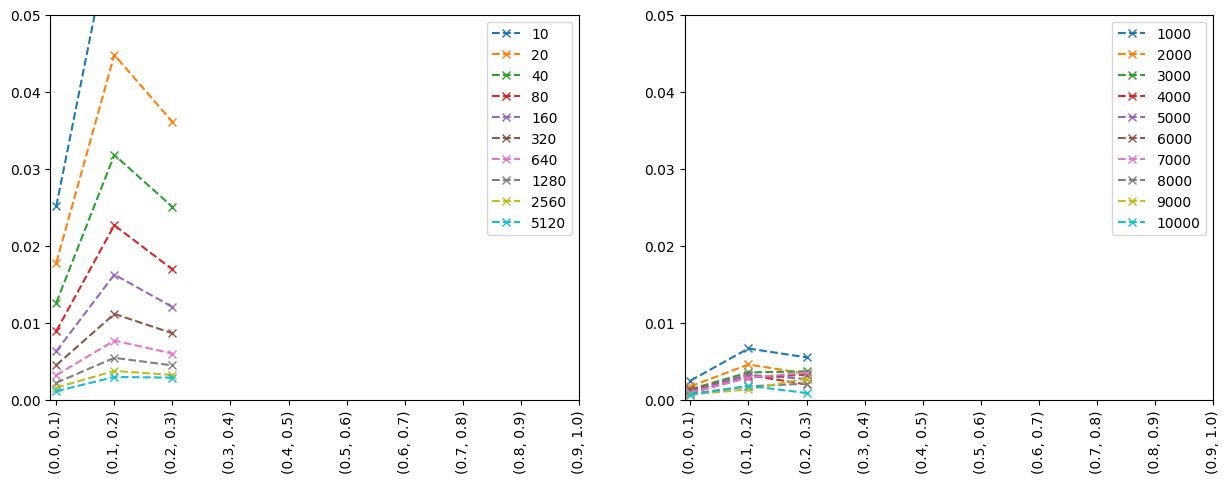

In [20]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))
stats_df_freq = pd.DataFrame(statistics_freq)
ax1 = stats_df_freq.plot(ax=ax1,marker="x",linestyle="--")
labels =ax1.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax1.set_xticklabels(stats_df_freq.index,rotation=90)
ax1.set_ylim([0,0.05])

stats_df_freq = pd.DataFrame(statistics_freq_higher_res)
ax2 = stats_df_freq.plot(ax=ax2,marker="x",linestyle="--")
labels =ax2.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax2.set_xticklabels(stats_df_freq.index,rotation=90)
ax2.set_ylim([0,0.05])


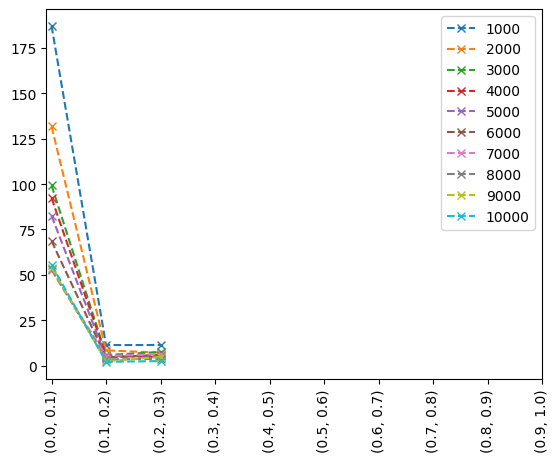

In [21]:
stats_df_freq = pd.DataFrame(statistics_freq_higher_res_cv)
ax = stats_df_freq.plot(marker="x",linestyle="--")
labels =ax.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax.set_xticklabels(stats_df_freq.index,rotation=90)

**Overview over results with filtering**

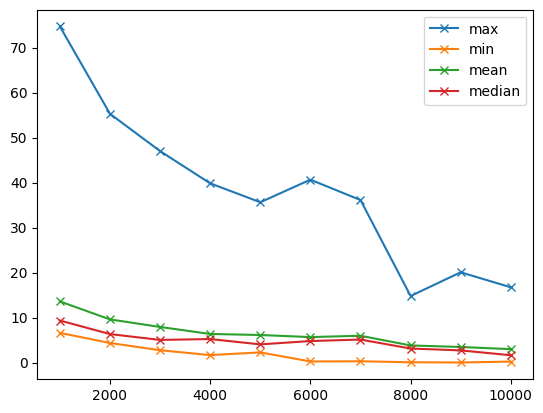

In [22]:
# For sample sizes of x calculate the frequency of the observation of values above 1e-6
sample_size=20000
data_freq = (dfs_tot_abs.T>1e-6).sum()/sample_size
index1 = data_freq>0.1

index2 = dfs_tot_abs.T.mean()>0.001
index = index1*index2
ax = pd.DataFrame(datas_higher_res_cv).loc[index].max().plot(marker='x',label="max")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].min().plot(ax=ax,marker='x',label="min")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].mean().plot(ax=ax,marker='x',label="mean")
ax = pd.DataFrame(datas_higher_res_cv).loc[index].median().plot(ax=ax,marker='x',label="median")
ax.legend()


In [23]:
pd.DataFrame(datas_higher_res_cv).loc[index].mean()

1000     13.582790
2000      9.586863
3000      7.905076
4000      6.350260
5000      6.121354
6000      5.657395
7000      5.951387
8000      3.799979
9000      3.455477
10000     2.979965
dtype: float64

In [24]:
data_high_df = pd.DataFrame(datas_higher_res_cv).loc[index][3000]

max_v = data_high_df.max()
data_high_df[data_high_df>0.5*max_v]

                                                           type
Collinsella_aerofaciens_ATCC_25986   M_hxan__91__e__93__   neg     41.927268
Eubacterium_rectale_ATCC_33656       M_succ__91__e__93__   pos     23.835405
                                     M_thr_L__91__e__93__  neg     42.113203
Faecalibacterium_prausnitzii_A2_165  M_ade__91__e__93__    neg     46.994223
                                     M_ser_L__91__e__93__  neg     29.901294
Name: 3000, dtype: float64

In [25]:
index_high = data_high_df[data_high_df>0.5*max_v].index
dfs_tot_abs.loc[index_high].T.mean()

                                                           type
Collinsella_aerofaciens_ATCC_25986   M_hxan__91__e__93__   neg     0.008802
Eubacterium_rectale_ATCC_33656       M_succ__91__e__93__   pos     0.012052
                                     M_thr_L__91__e__93__  neg     0.010020
Faecalibacterium_prausnitzii_A2_165  M_ade__91__e__93__    neg     0.003914
                                     M_ser_L__91__e__93__  neg     0.007582
dtype: float64

## E.coli mutants community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 5:995 => has to increase 200 times)

$$
X_1/X_0 = 200 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(200)}{t}
$$

**Methods (From Guillen et al. 2021): 1:200 dilution every 24 h**

In [3]:
np.log(200)/24

np.float64(0.22076322360616818)

**Input data**

In [4]:
mediadb = "../data/Guillen2021/generated/media_db.tsv"#path to mediadb
medium = "M9"
growth = np.log(200)/24 

models = ["../models/Guillen2021/top_7_strains/"+name for name in listdir("../models/Guillen2021/top_7_strains/")]
communities = "../data/Guillen2021/generated/communities_smetana.tsv"

comm_id = "ecoli_auxotrophs"

output_dir = "../output/Guillen2021/convergence_test_no_abundance/"

**Run SteadierSample**

**Load SteadierSample results**

In [6]:
direct = listdir("../output/Guillen2021/convergence_test_no_abundance/")

dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Guillen2021/convergence_test_no_abundance/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
#dfs_tot = dfs_tot.fillna(0)


# Separate positive and degative values
pos = dfs_tot[dfs_tot>0].dropna(how="all").copy()
neg = dfs_tot[dfs_tot<0].dropna(how="all").map(abs).copy()

neg["type"]="neg"
pos["type"]="pos"
neg.set_index("type",append=True,inplace=True)
pos.set_index("type",append=True,inplace=True)

dfs_tot_abs_nan = pd.concat([pos,neg],axis=0)
dfs_tot_abs = dfs_tot_abs_nan.fillna(0)

### Plotting standard deviation based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the standard deviation across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [7]:
base = 10
sample_sizes = [int(base * 2**i) for i in range(12)] 
sample_sizes = [s for s in sample_sizes if s<10000]

sample_sizes_higher_res = np.arange(1000,11000,1000)
sample_sizes_lower_res = np.arange(100,1000,100)


datas,datas_cv = std_sample_size(dfs_tot_abs,sample_sizes)
datas_higher_res,datas_higher_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_higher_res)
datas_lower_res,datas_lower_res_cv = std_sample_size(dfs_tot_abs,sample_sizes_lower_res)

Text(0.5, 0, 'Number of samples')

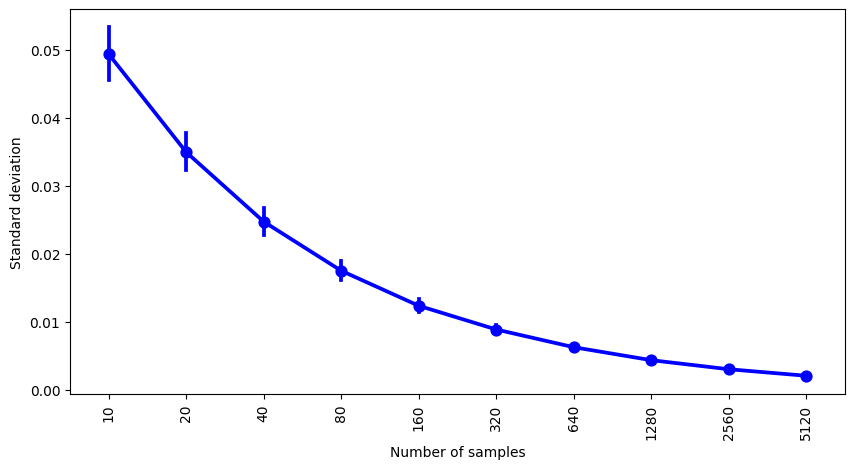

In [9]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)

ax.set_ylabel("Standard deviation")
ax.set_xlabel("Number of samples")
#plt.savefig("figures_meeting/convergence_ecoli_noabund.png",bbox_inches="tight")

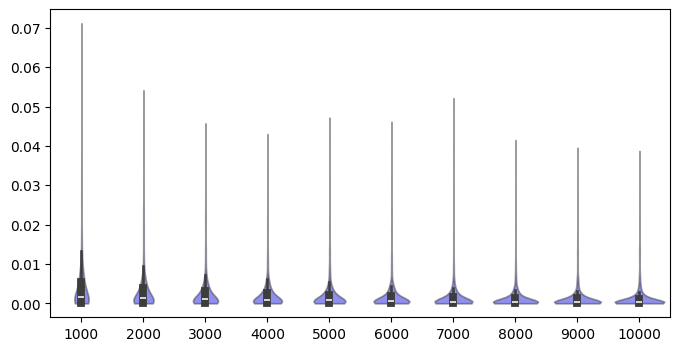

In [10]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

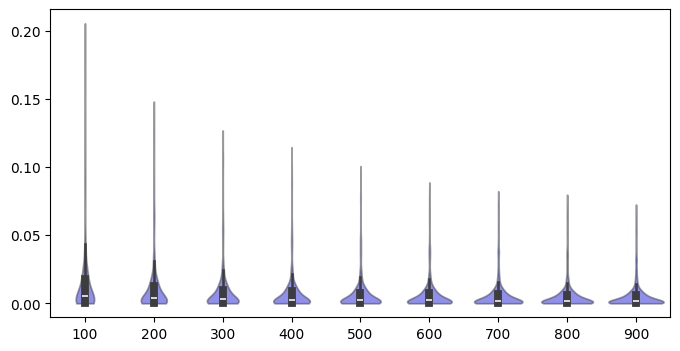

In [11]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_lower_res),cut=0,ax=ax,color="blue",alpha=0.5)
#ax.set_ylim([0,1e-2])

### Plotting standard deviation based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [12]:
statistics,statistics_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes)

statistics_higher_res,statistics_higher_res_cv = std_sampling_grouped(dfs_tot_abs,sample_sizes_higher_res)
       

(0.0, 0.2)

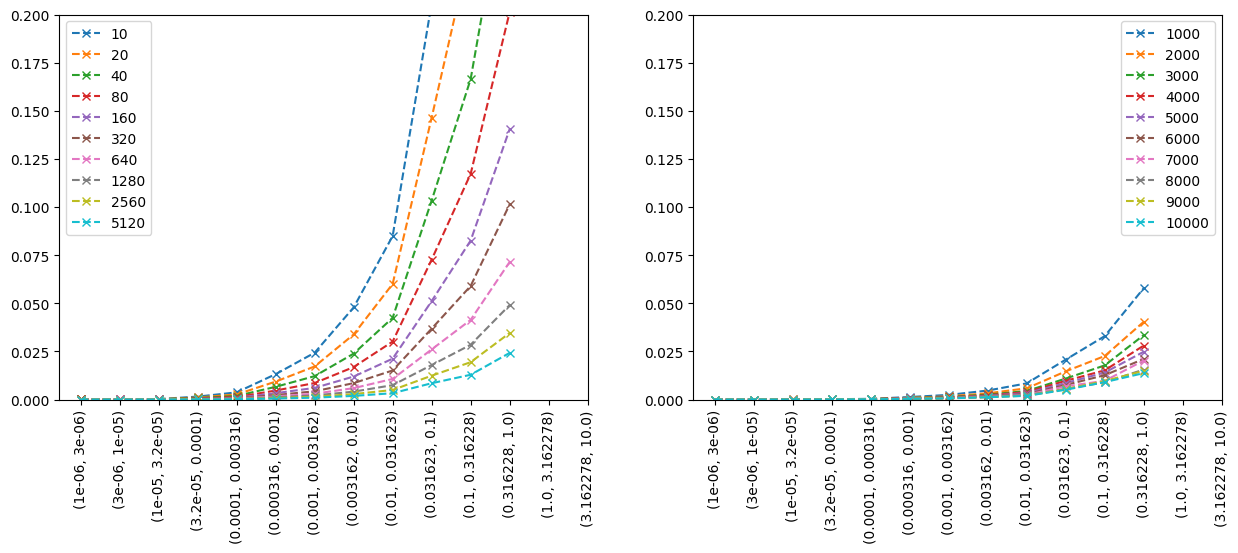

In [13]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))

ax1 = pd.DataFrame(statistics).plot(ax=ax1,marker="x",linestyle="--")
ax1.set_xticks(np.arange(0,len(pd.DataFrame(statistics).index.values)))
ax1.set_xticklabels(pd.DataFrame(statistics).index.values,rotation=90)
ax1.legend(loc="upper left")
ax1.set_ylim([0,0.2])

ax2 = pd.DataFrame(statistics_higher_res).plot(ax=ax2,marker="x",linestyle="--")
ax2.set_xticks(np.arange(0,len(pd.DataFrame(statistics_higher_res).index.values)))
ax2.set_xticklabels(pd.DataFrame(statistics_higher_res).index.values,rotation=90)
ax2.legend(loc="upper right")
ax2.set_ylim([0,0.2])

(0.0, 100.0)

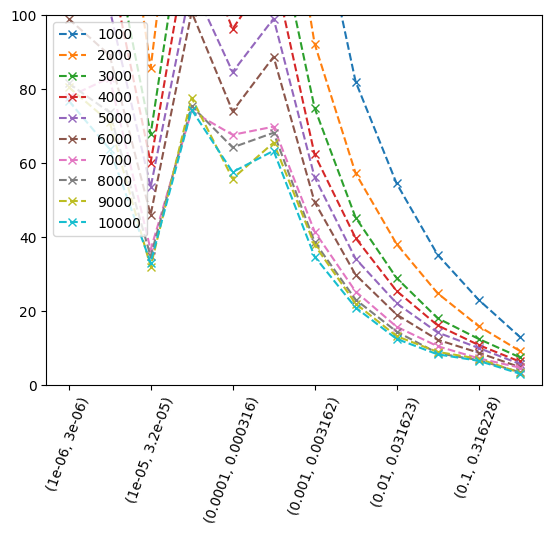

In [14]:
ax = pd.DataFrame(statistics_higher_res_cv).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)
plt.legend(loc="upper left")
ax.set_ylim([0,100])

In [15]:
stats_high_res = pd.DataFrame(statistics_higher_res_cv)
diff = (stats_high_res.T.iloc[1:].reset_index(drop=True)-stats_high_res.T.iloc[:-1].reset_index(drop=True))

index = pd.Index(list(zip(np.arange(1000,10000,1000),np.arange(2000,11000,1000))))
diff.set_index(keys=index,inplace=True)

In [16]:
diff.T.mean()

1000  2000    -39.402036
2000  3000    -19.814298
3000  4000     -8.228427
4000  5000     -7.893442
5000  6000     -6.710841
6000  7000     -9.000445
7000  8000     -1.755001
8000  9000     -1.483484
9000  10000    -1.671833
dtype: float64

**Sort based on frequency**

In [17]:
statistics_freq,statistics_freq_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes)
statistics_freq_higher_res, statistics_freq_higher_res_cv = std_sampling_grouped_freq(dfs_tot_abs,sample_sizes_higher_res)

(0.0, 0.05)

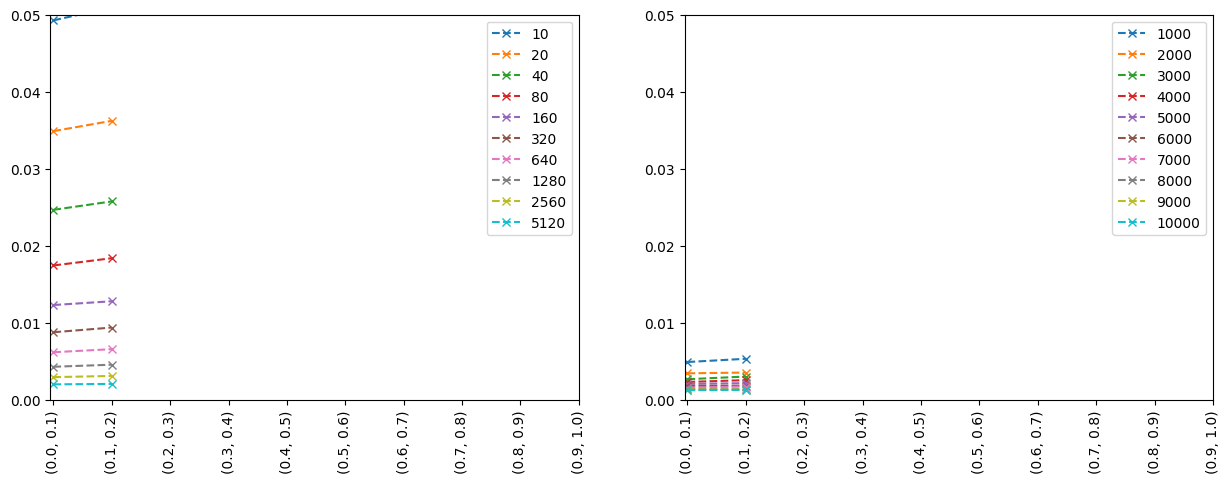

In [18]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(15,5))
stats_df_freq = pd.DataFrame(statistics_freq)
ax1 = stats_df_freq.plot(ax=ax1,marker="x",linestyle="--")
labels =ax1.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax1.set_xticklabels(stats_df_freq.index,rotation=90)
ax1.set_ylim([0,0.05])

stats_df_freq = pd.DataFrame(statistics_freq_higher_res)
ax2 = stats_df_freq.plot(ax=ax2,marker="x",linestyle="--")
labels =ax2.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax2.set_xticklabels(stats_df_freq.index,rotation=90)
ax2.set_ylim([0,0.05])


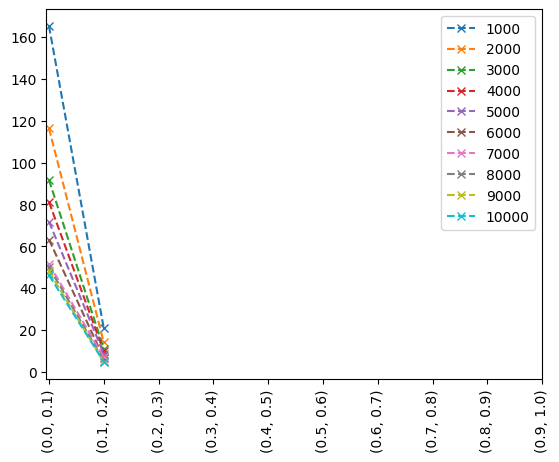

In [19]:
stats_df_freq = pd.DataFrame(statistics_freq_higher_res_cv)
ax = stats_df_freq.plot(marker="x",linestyle="--")
labels =ax.set_xticks(np.arange(len(stats_df_freq.index)))
labels = ax.set_xticklabels(stats_df_freq.index,rotation=90)

**Overview over results with filtering**

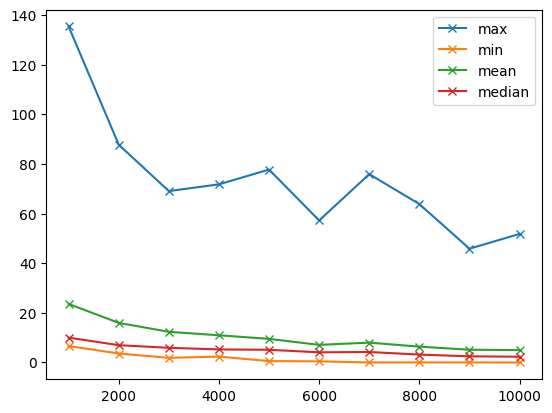

In [20]:
# For sample sizes of x calculate the frequency of the observation of values above 1e-6
sample_size=20000
data_freq = (dfs_tot_abs.T>1e-6).sum()/sample_size
index1 = data_freq>0.1

index2 = dfs_tot_abs.T.mean()>0.001
index = index1*index2

data_high_all_df = pd.DataFrame(datas_higher_res_cv)
ax = data_high_all_df.loc[index].max().plot(marker='x',label="max")
ax = data_high_all_df.loc[index].min().plot(ax=ax,marker='x',label="min")
ax = data_high_all_df.loc[index].mean().plot(ax=ax,marker='x',label="mean")
ax = data_high_all_df.loc[index].median().plot(ax=ax,marker='x',label="median")
ax.legend()


In [21]:
pd.DataFrame(datas_higher_res_cv).loc[index].mean()

1000     23.588811
2000     15.949517
3000     12.352069
4000     10.955567
5000      9.508987
6000      7.093940
7000      7.997288
8000      6.383887
9000      5.136734
10000     4.981438
dtype: float64

In [22]:
data_high_df = pd.DataFrame(datas_higher_res_cv).loc[index][3000]

max_v = data_high_df.max()
data_high_df[data_high_df>0.5*max_v]

                                   type
mutant_bioF  M_fe2_e               neg     55.723077
mutant_bioH  M_fe2_e               neg     46.896181
mutant_cysW  M_LalaDgluMdapDala_e  neg     57.758371
             M_fe2_e               neg     35.528941
             M_gam6p_e             neg     43.719344
mutant_icd   M_fe2_e               neg     62.616032
mutant_panD  M_alaala_e            neg     36.754549
             M_fe2_e               neg     57.125343
mutant_panZ  M_LalaDgluMdapDala_e  neg     69.055613
             M_fe2_e               neg     59.763762
             M_thymd_e             neg     51.891786
Name: 3000, dtype: float64

In [23]:
index_high = data_high_df[data_high_df>0.5*max_v].index
dfs_tot_abs.loc[index_high].T.mean()

                                   type
mutant_bioF  M_fe2_e               neg     0.004664
mutant_bioH  M_fe2_e               neg     0.002182
mutant_cysW  M_LalaDgluMdapDala_e  neg     0.002998
             M_fe2_e               neg     0.007564
             M_gam6p_e             neg     0.002262
mutant_icd   M_fe2_e               neg     0.004658
mutant_panD  M_alaala_e            neg     0.002165
             M_fe2_e               neg     0.004970
mutant_panZ  M_LalaDgluMdapDala_e  neg     0.003474
             M_fe2_e               neg     0.003881
             M_thymd_e             neg     0.005160
dtype: float64